# 07 Haze: does the 13-band advantage hold in hazy images?

**Purpose.** Answer SQ4: does the 13-band advantage still hold when the images are hazy, both with haze that affects every band equally and with haze that, as in reality, affects short wavelengths most? The saved models of notebooks 03 to 05 predict the same test patches with simulated haze of increasing thickness; nothing is retrained.

**Functions.** `src/piece_of_crop/haze.py` (`haze_share`, `add_haze`, `hazy_test_loader`, `rf_hazy_probabilities`, `WAVELENGTHS_NM`), `evaluate.py` (`insurer_cost_matrix`, `block_bootstrap_ci`), `train.py` (`predict`), `cnn.py` (`SmallCNN`) and `resnet.py` (`build_resnet`, `IMAGE_SIZE`).

**Reads.** `results/split.csv`, `results/band_stats.csv`, the clean test predictions in `results/predictions/`, the 18 saved models in `models/` and the patch cache `data/eurosat_cache.npy`.

**Saves.** `results/haze_runs.csv`, `results/haze_differences.csv` and the figures `results/figures/haze_*.png`. The predictions on hazy patches are not saved per patch, because the summary tables hold everything the report uses.

## 1. Setup

In [1]:
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score
from IPython.display import display

from piece_of_crop import BAND_NAMES, CLASS_NAMES, MODEL_FILES, RGB_BAND_INDICES, read_split, get_cache
from piece_of_crop import SmallCNN, build_resnet, IMAGE_SIZE, predict
from piece_of_crop import WAVELENGTHS_NM, haze_share, add_haze, hazy_test_loader, rf_hazy_probabilities
from piece_of_crop import insurer_cost_matrix, block_bootstrap_ci

SEEDS = (0, 1, 2)
INPUTS = ("rgb", "13band")
MODELS = tuple(MODEL_FILES)  # RandomForest, SmallCNN, ResNet18
PROFILES = ("uniform", "wavelength")
HAZE_LEVELS = (0.01, 0.02, 0.05, 0.10, 0.20, 0.40, 0.63)  # share of haze at 550 nm, see section 2
N_BOOTSTRAP = 2000
BOOTSTRAP_SEED = 0

project_root = Path.cwd().parents[0]
data_dir = project_root / "data" / "EuroSAT_MS"
results_dir = project_root / "results"
figures_dir = results_dir / "figures"
predictions_dir = results_dir / "predictions"
models_dir = project_root / "models"

split = read_split(results_dir / "split.csv")
band_stats = pd.read_csv(results_dir / "band_stats.csv")
cache = get_cache(split, data_dir, project_root / "data" / "eurosat_cache.npy")
test_rows = split[split["split"].eq("test")].reset_index(drop=True)
y_true = test_rows["label"].to_numpy()
blocks = test_rows["block"].to_numpy()
label_ids = np.arange(len(CLASS_NAMES))
costs = insurer_cost_matrix()
critical = costs >= 8  # as in notebook 06
airlight = band_stats["clip_high"].to_numpy(dtype=np.float32)
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")

print("Device:", device, "| test patches:", len(test_rows))

Device: mps | test patches: 3854


## 2. The haze model

**Claim.** We simulate haze with the standard model of a hazy image, with the haze per band set by physics, so that every step can be checked. The strength of the haze is a share we choose, not a measured haze level.

**How it works.** A hazy value is the clear value seen through the haze plus the light that the haze itself scatters towards the sensor:

hazy = (1 − share) × clear + share × airlight

This is the model "widely used to describe the formation of a hazy image" (external: He, Sun and Tang, 2011, "Single Image Haze Removal Using Dark Channel Prior", *IEEE TPAMI* 33(12), equation 1). We build it from three parts:

1. **Strength: the share of haze at 550 nm** (green light), at seven levels: 1%, 2%, 5%, 10%, 20%, 40% and 63%. Each step is at most about twice the one before, and most lie below 20%, where the first version showed the models starting to fail (see below).
2. **Haze per band: the Ångström law.** Haze scatters short wavelengths more: the optical depth at wavelength λ is the optical depth at 550 nm × (λ / 550 nm)^−α. The exponent was introduced by Ångström in 1929, and its average for natural atmospheres is about 1.3, within a typical range of 0.5 to 2.5 (external: instesre.org/Aerosols/angstrom.htm). The central wavelengths of the bands are those published by the USGS (external: USGS EROS Archive, Sentinel-2).
3. **From optical depth to share.** Light that crosses a layer of optical depth τ is reduced to exp(−τ) of its strength on a vertical path (Beer–Lambert law; external: Penn State, METEO 300, section 6.10). It crosses the haze twice, from the sun to the ground and back up, so the share of haze in a band is 1 − exp(−2τ). The table below shows the result: at 20% in green, blue (B02) gets 23% and B12 only 4%.

The **airlight** is the brightness of the haze itself. We set it to the brightest normal value of each band, the training 99.9th percentile from notebook 02, so that thick haze turns a patch bright and pale. The **uniform** profile gives every band the share of 550 nm. It is not realistic; it is a control. If the 13 bands hold up better only under the wavelength profile, the reason is that the infrared bands see through the haze, not that there are more bands.

Haze is added to the raw bands, which are then clipped and normalised with the clean training statistics, exactly what a deployed model would receive. No model is retrained, as in the course's adversarial examples, where a trained model is given "slightly modified" inputs to see whether its predictions change (lecture_15_intro_to_generative_models.pdf, slide 8).

**Why the strength is a share and not a real haze measure.** Our first version expressed the strength as aerosol optical depth (AOD), the standard measure of haze, at four levels taken from a NOAA guide: 0.1 (clean), 0.3 (thin), 0.5 (moderately thick) and 0.8 (thick). Its results showed that this scale was wrong in our model. At AOD 0.1, which NOAA calls a clean atmosphere, the 13-band CNN dropped from 95% to 44% accuracy, and the example patch was already washed out at AOD 0.3, which real satellite images on such a day are not. The reason is the airlight: the haze model comes from photographs taken along the ground, where haze in front of a distant hill is as bright as the horizon sky, while a satellite looks straight down through a thin layer whose scattered light is much dimmer. Our bright airlight, and leaving out the scattered light that still reaches the sensor, make the haze several times too strong for a given AOD. We therefore report the strength as the share of haze at 550 nm and make no claim about which real AOD each level matches. The highest level, 63%, equals the old AOD 0.5. The first version is kept in the project history (Git commit 14e3979).

**Counterargument.** Without a calibrated scale, we cannot say how hazy a real day must be for a model to fail, only how the models and inputs compare as the haze grows. We accept this: SQ4 asks whether the 13-band advantage holds under haze, which is a comparison, and both inputs get exactly the same haze.

Share of haze in each band (bands in wavelength order):


,B01,B02,B03,B04,B05,B06,B07,B08,B8A,B09,B10,B11,B12
"uniform, 1%",0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01
"uniform, 2%",0.02,0.02,0.02,0.02,0.02,0.02,0.02,0.02,0.02,0.02,0.02,0.02,0.02
"uniform, 5%",0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05
"uniform, 10%",0.10,0.10,0.10,0.10,0.10,0.10,0.10,0.10,0.10,0.10,0.10,0.10,0.10
"uniform, 20%",0.20,0.20,0.20,0.20,0.20,0.20,0.20,0.20,0.20,0.20,0.20,0.20,0.20
"uniform, 40%",0.40,0.40,0.40,0.40,0.40,0.40,0.40,0.40,0.40,0.40,0.40,0.40,0.40
"uniform, 63%",0.63,0.63,0.63,0.63,0.63,0.63,0.63,0.63,0.63,0.63,0.63,0.63,0.63
"wavelength, 1%",0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.00,0.00,0.00,0.00
"wavelength, 2%",0.03,0.02,0.02,0.02,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.00,0.00
"wavelength, 5%",0.07,0.06,0.05,0.04,0.04,0.03,0.03,0.03,0.03,0.03,0.02,0.01,0.01


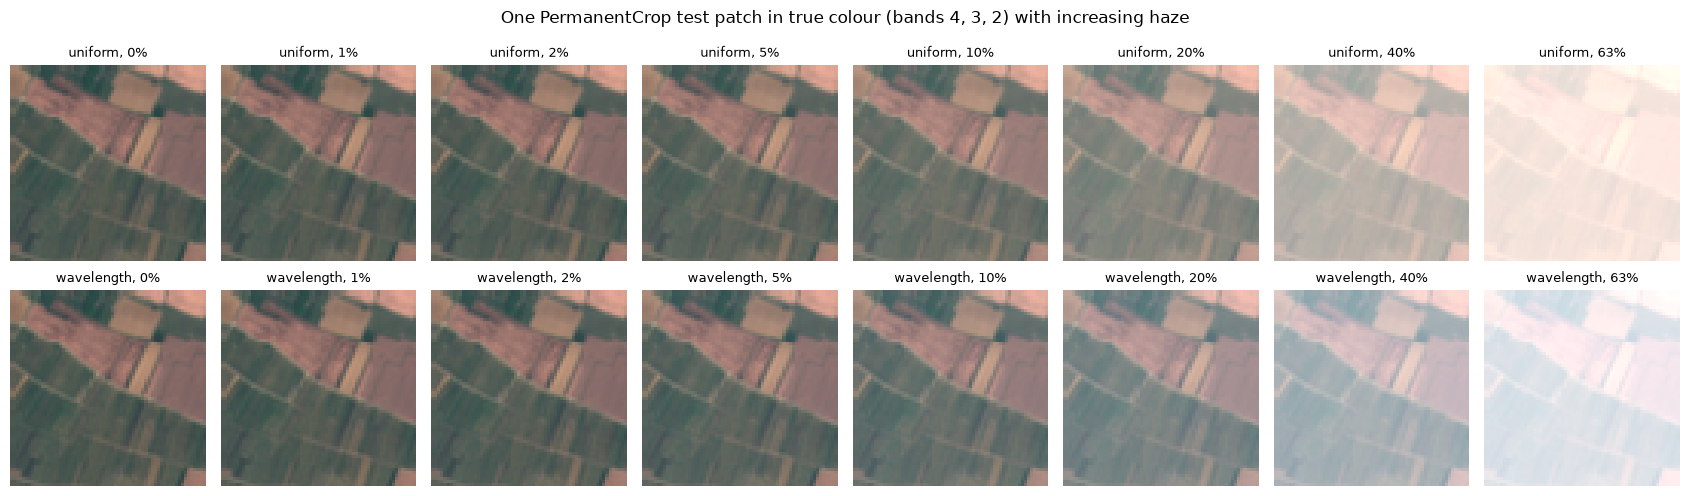

In [2]:
# share of each band's value that comes from the haze, (1 - t)
share_table = pd.DataFrame({f"{profile}, {strength:.0%}": haze_share(strength, profile) for profile in PROFILES for strength in HAZE_LEVELS},
                           index=BAND_NAMES).T
order = [BAND_NAMES[k] for k in np.argsort(WAVELENGTHS_NM)]
print("Share of haze in each band (bands in wavelength order):")
display(share_table[order].round(2))

# one patch at every level, on a fixed display scale so the haze is visible
example = int(np.where(y_true == CLASS_NAMES.index("PermanentCrop"))[0][0])
clear = np.asarray(cache[test_rows["cache_row"][example]], dtype=np.float32)
fig, axes = plt.subplots(2, len(HAZE_LEVELS) + 1, figsize=(17, 5.2))
for row, profile in enumerate(PROFILES):
    for col, strength in enumerate((0.0,) + HAZE_LEVELS):
        image = add_haze(clear, strength, profile, airlight)[RGB_BAND_INDICES].transpose(1, 2, 0)
        axes[row, col].imshow(np.clip(image / 3000, 0, 1))
        axes[row, col].set_title(f"{profile}, {strength:.0%}", fontsize=9)
        axes[row, col].axis("off")
fig.suptitle("One PermanentCrop test patch in true colour (bands 4, 3, 2) with increasing haze")
fig.tight_layout()
fig.savefig(figures_dir / "haze_example_patch.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Predict every saved model on the hazy test patches

For each of the 18 saved models (3 models x 2 inputs x 3 seeds), the clean test set is predicted first and compared with the predictions saved in notebooks 03 to 05: they must agree, otherwise the haze results would not be comparable with notebook 06. Then each model predicts the test set at the seven haze levels of both profiles. For every run we keep accuracy, macro-F1, the critical-error rate and cost per patch of notebook 06, and how often HerbaceousVegetation is called Forest, the confusion that notebook 06 linked to the extra bands.

In [3]:
def load_model(model, input_type, seed):
    prefix = MODEL_FILES[model]
    if model == "RandomForest":
        forest = joblib.load(models_dir / f"{prefix}_{input_type}_seed{seed}.joblib")
        assert list(forest.classes_) == list(label_ids)  # probability columns are classes 0 to 9
        return forest
    channels = 3 if input_type == "rgb" else 13
    net = SmallCNN(in_channels=channels, num_classes=len(CLASS_NAMES)) if model == "SmallCNN" else \
        build_resnet(in_channels=channels, num_classes=len(CLASS_NAMES), pretrained=False)
    net.load_state_dict(torch.load(models_dir / f"{prefix}_{input_type}_seed{seed}.pt", map_location="cpu"))
    return net.to(device)


def predict_hazy(model_name, model, input_type, strength, profile):
    if model_name == "RandomForest":
        return rf_hazy_probabilities(model, test_rows, cache, band_stats, input_type, strength, profile, airlight).argmax(axis=1)
    image_size = IMAGE_SIZE if model_name == "ResNet18" else None
    loader = hazy_test_loader(test_rows, cache, band_stats, input_type, strength, profile, airlight, image_size)
    labels, proba = predict(model, loader, device)
    assert np.array_equal(labels, y_true)  # same patches in the same order
    return proba.argmax(axis=1)


herb, forest_id = CLASS_NAMES.index("HerbaceousVegetation"), CLASS_NAMES.index("Forest")
hazy_predictions, run_rows = {}, []
for model_name in MODELS:
    for input_type in INPUTS:
        for seed in SEEDS:
            start = time.time()
            model = load_model(model_name, input_type, seed)
            saved = pd.read_csv(predictions_dir / f"{MODEL_FILES[model_name]}_{input_type}_seed{seed}.csv")["y_pred"].to_numpy()
            clean = predict_hazy(model_name, model, input_type, 0.0, "uniform")
            agreement = (clean == saved).mean()
            assert agreement >= 0.999, f"clean predictions differ from the saved ones ({agreement:.4f})"
            conditions = [("none", 0.0, clean)] + [(profile, strength, predict_hazy(model_name, model, input_type, strength, profile))
                                                   for profile in PROFILES for strength in HAZE_LEVELS]
            for profile, strength, y_pred in conditions:
                hazy_predictions[(model_name, input_type, seed, profile, strength)] = y_pred
                run_rows.append({"model": model_name, "input": input_type, "seed": seed, "profile": profile, "haze_550": strength,
                                 "accuracy": accuracy_score(y_true, y_pred),
                                 "macro_f1": f1_score(y_true, y_pred, average="macro"),
                                 "critical_error_rate": critical[y_true, y_pred].mean(),
                                 "cost_per_patch": costs[y_true, y_pred].mean(),
                                 "herb_called_forest": int(((y_true == herb) & (y_pred == forest_id)).sum())})
            print(f"{model_name} {input_type} seed {seed}: clean agreement {agreement:.4f}, {time.time() - start:.0f} s")

haze_runs = pd.DataFrame(run_rows)
haze_runs.to_csv(results_dir / "haze_runs.csv", index=False)

RandomForest rgb seed 0: clean agreement 1.0000, 15 s
RandomForest rgb seed 1: clean agreement 1.0000, 13 s
RandomForest rgb seed 2: clean agreement 1.0000, 13 s
RandomForest 13band seed 0: clean agreement 1.0000, 13 s
RandomForest 13band seed 1: clean agreement 1.0000, 13 s
RandomForest 13band seed 2: clean agreement 1.0000, 13 s
SmallCNN rgb seed 0: clean agreement 1.0000, 18 s
SmallCNN rgb seed 1: clean agreement 1.0000, 19 s
SmallCNN rgb seed 2: clean agreement 1.0000, 16 s
SmallCNN 13band seed 0: clean agreement 1.0000, 19 s
SmallCNN 13band seed 1: clean agreement 1.0000, 19 s
SmallCNN 13band seed 2: clean agreement 1.0000, 19 s
ResNet18 rgb seed 0: clean agreement 1.0000, 144 s
ResNet18 rgb seed 1: clean agreement 1.0000, 152 s
ResNet18 rgb seed 2: clean agreement 1.0000, 164 s
ResNet18 13band seed 0: clean agreement 1.0000, 250 s
ResNet18 13band seed 1: clean agreement 1.0000, 259 s
ResNet18 13band seed 2: clean agreement 1.0000, 256 s


**Check.** All 18 models predict the clean test set exactly as in notebooks 03 to 05 (agreement 1.0000 for every model), so the haze results below start from the same clean results as notebook 06, and any change comes from the haze alone.

## 4. Accuracy and critical errors as the haze thickens

Mean over the three seeds. 0% is the clean test set; solid lines are 13 bands, dashed lines RGB.

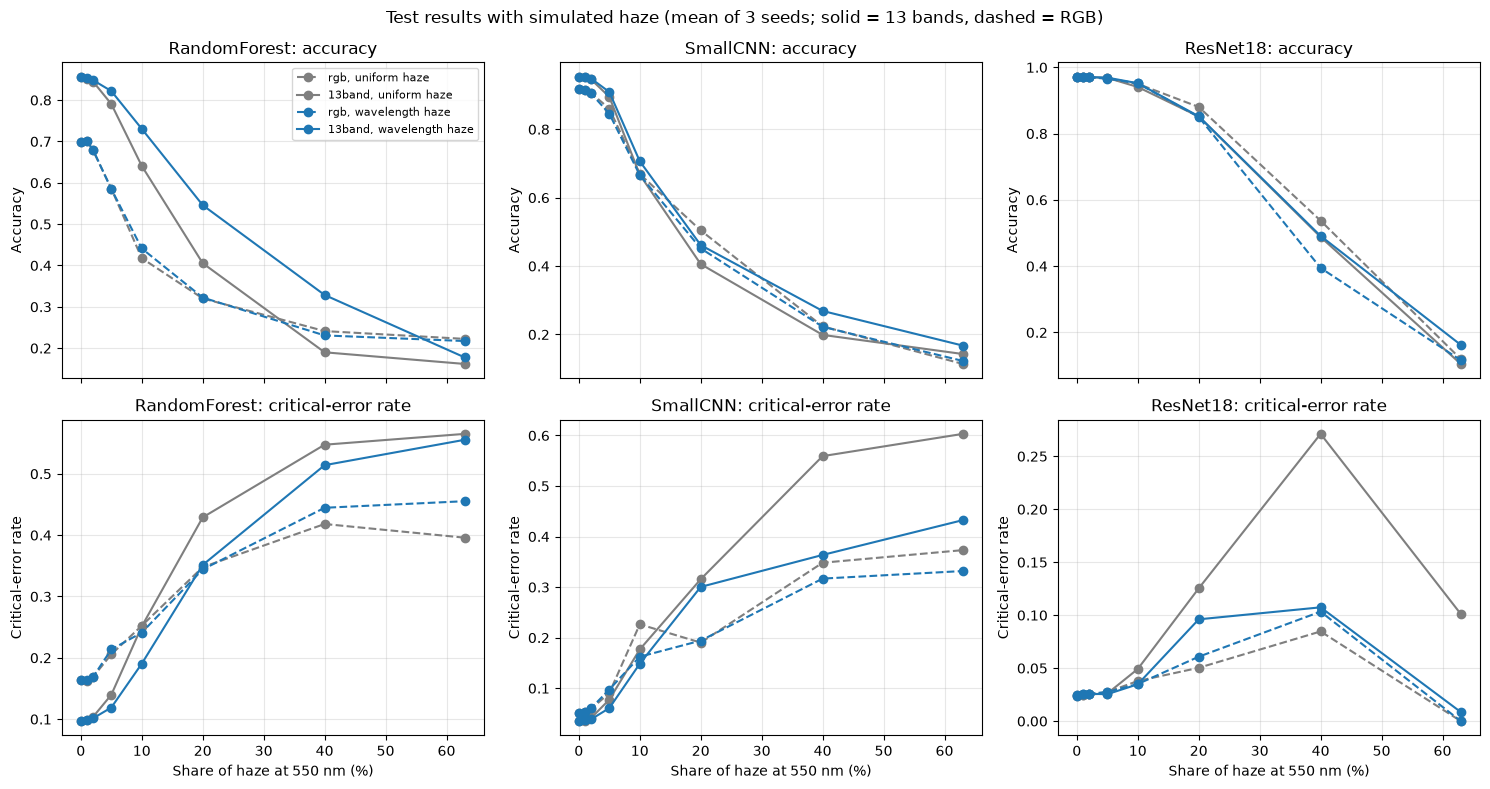

input                               rgb  13band
model        profile    haze_550               
RandomForest uniform    0.00      0.698   0.857
                        0.01      0.702   0.852
                        0.02      0.678   0.845
                        0.05      0.586   0.791
                        0.10      0.418   0.641
                        0.20      0.320   0.406
                        0.40      0.241   0.190
                        0.63      0.222   0.162
             wavelength 0.00      0.698   0.857
                        0.01      0.701   0.853
                        0.02      0.680   0.848
                        0.05      0.585   0.822
                        0.10      0.441   0.731
                        0.20      0.322   0.546
                        0.40      0.231   0.329
                        0.63      0.217   0.178
ResNet18     uniform    0.00      0.972   0.972
                        0.01      0.971   0.971
                        0.02      0.970   0.971
                        0.05      0.967   0.968
                        0.10      0.950   0.941
                        0.20      0.881   0.852
                        0.40      0.537   0.488
                        0.63      0.120   0.105
             wavelength 0.00      0.972   0.972
                        0.01      0.971   0.971
                        0.02      0.970   0.970
                        0.05      0.966   0.969
                        0.10      0.952   0.952
                        0.20      0.850   0.853
                        0.40      0.395   0.491
                        0.63      0.116   0.162
SmallCNN     uniform    0.00      0.918   0.954
                        0.01      0.914   0.952
                        0.02      0.906   0.946
                        0.05      0.861   0.895
                        0.10      0.669   0.667
                        0.20      0.504   0.406
                        0.40      0.224   0.199
                        0.63      0.114   0.143
             wavelength 0.00      0.918   0.954
                        0.01      0.915   0.952
                        0.02      0.905   0.949
                        0.05      0.846   0.909
                        0.10      0.666   0.707
                        0.20      0.452   0.461
                        0.40      0.223   0.269
                        0.63      0.123   0.168

In [4]:
# clean results count for both profiles
clean_rows = haze_runs[haze_runs["profile"].eq("none")]
curves = pd.concat([haze_runs[~haze_runs["profile"].eq("none")]] + [clean_rows.assign(profile=p) for p in PROFILES])
means = curves.groupby(["model", "input", "profile", "haze_550"])[["accuracy", "critical_error_rate"]].mean().reset_index()

fig, axes = plt.subplots(2, len(MODELS), figsize=(15, 8), sharex=True)
colours = {"uniform": "tab:grey", "wavelength": "tab:blue"}
for col, model_name in enumerate(MODELS):
    for row, (measure, label) in enumerate((("accuracy", "Accuracy"), ("critical_error_rate", "Critical-error rate"))):
        ax = axes[row, col]
        for profile in PROFILES:
            for input_type in INPUTS:
                line = means[(means["model"] == model_name) & (means["profile"] == profile) & (means["input"] == input_type)]
                ax.plot(line["haze_550"] * 100, line[measure], marker="o", color=colours[profile],
                        ls="-" if input_type == "13band" else "--", label=f"{input_type}, {profile} haze")
        ax.set(title=f"{model_name}: {label.lower()}", ylabel=label)
        ax.grid(alpha=0.3)
        if row == 1:
            ax.set_xlabel("Share of haze at 550 nm (%)")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Test results with simulated haze (mean of 3 seeds; solid = 13 bands, dashed = RGB)")
fig.tight_layout()
fig.savefig(figures_dir / "haze_curves.png", dpi=150, bbox_inches="tight")
plt.show()

display(means.pivot_table(index=["model", "profile", "haze_550"], columns="input", values="accuracy", sort=False)[list(INPUTS)].round(3))

**Claim.** Light haze does not matter, but every model breaks down as the haze thickens, and the pretrained ResNet holds out longest.

**Reasons.** All models were trained on clear patches only. Haze brightens every band and flattens the differences between them, so the patches drift away from anything the models have seen. The ResNet starts from features learned on very varied photographs, which makes it less sensitive to such a shift.

**Evidence.** Up to 2% haze, no model loses more than 1.9 points of accuracy. At 5%, the CNN loses 3 to 6 points and the random forest up to 11 points (RGB, 69.8% to 58.6%), while the ResNet loses at most 0.6 points. At 10%, the CNN falls to 67 to 71%, the 13-band random forest to 64% (uniform) or 73% (wavelength), and the ResNet stays at 94 to 95%. At 20%, the ResNet is at 85 to 88%, while the CNN is at 41 to 50%. At 63%, all models are close to or at the level of guessing. In the example patch, the fields are still clearly visible at 20% and pale at 40%.

**Warrant.** A model can only be trusted on inputs like those it was trained on; haze moves the inputs away from that, and the curves show how far each model can be moved before it fails. This is the same idea as the course's adversarial examples, where changed inputs make a trained model err (lecture_15_intro_to_generative_models.pdf, slide 8), but with a natural change instead of a crafted one.

**Counterargument.** At 63% the critical-error rate of the ResNet falls again, to 0 to 10%. This is not an improvement: with an accuracy of 11 to 16%, the networks predict almost every patch as the same few classes, and those happen not to be counted as critical against farmland. Critical-error rates above about 40% haze therefore say little.

## 5. The 13-band advantage at each haze level, with intervals

As in notebook 06: for every model and condition, the 13-band minus RGB difference per test patch, averaged over the seeds, with a 95% block-bootstrap interval. A positive accuracy difference and a negative critical-error difference favour the 13 bands. If the advantage holds under haze, the intervals of the random forest and the CNN stay away from 0 as the haze thickens.

In [5]:
rng = np.random.default_rng(BOOTSTRAP_SEED)
conditions = [("none", 0.0)] + [(p, h) for p in PROFILES for h in HAZE_LEVELS]
difference_rows = []
for model_name in MODELS:
    for profile, strength in conditions:
        for measure, per_patch in (("accuracy", lambda p: (p == y_true).astype(float)),
                                   ("critical_error_rate", lambda p: critical[y_true, p].astype(float))):
            per_seed = np.array([per_patch(hazy_predictions[(model_name, "13band", s, profile, strength)])
                                 - per_patch(hazy_predictions[(model_name, "rgb", s, profile, strength)]) for s in SEEDS])
            low, high = block_bootstrap_ci(per_seed.mean(axis=0), blocks, N_BOOTSTRAP, rng)
            difference_rows.append({"model": model_name, "profile": profile, "haze_550": strength, "measure": measure,
                                    "13band_minus_rgb": per_seed.mean(), "ci_low": low, "ci_high": high,
                                    "excludes_0": not (low <= 0 <= high)})

haze_differences = pd.DataFrame(difference_rows)
haze_differences.to_csv(results_dir / "haze_differences.csv", index=False)
display(haze_differences[haze_differences["measure"].eq("accuracy")].round(4))
display(haze_differences[haze_differences["measure"].eq("critical_error_rate")].round(4))

,model,profile,haze_550,measure,13band_minus_rgb,ci_low,ci_high,excludes_0
0,RandomForest,none,0.00,accuracy,0.1582,0.1207,0.1992,True
2,RandomForest,uniform,0.01,accuracy,0.1501,0.1148,0.1892,True
4,RandomForest,uniform,0.02,accuracy,0.1667,0.1298,0.2059,True
6,RandomForest,uniform,0.05,accuracy,0.2049,0.1565,0.2577,True
8,RandomForest,uniform,0.10,accuracy,0.2232,0.1488,0.3046,True
10,RandomForest,uniform,0.20,accuracy,0.0852,0.0320,0.1468,True
12,RandomForest,uniform,0.40,accuracy,-0.0513,-0.1678,0.0444,False
14,RandomForest,uniform,0.63,accuracy,-0.0606,-0.1671,0.0452,False
16,RandomForest,wavelength,0.01,accuracy,0.1525,0.1145,0.1934,True
18,RandomForest,wavelength,0.02,accuracy,0.1682,0.1302,0.2094,True


,model,profile,haze_550,measure,13band_minus_rgb,ci_low,ci_high,excludes_0
1,RandomForest,none,0.00,critical_error_rate,-0.0675,-0.1040,-0.0350,True
3,RandomForest,uniform,0.01,critical_error_rate,-0.0636,-0.0970,-0.0349,True
5,RandomForest,uniform,0.02,critical_error_rate,-0.0652,-0.0997,-0.0371,True
7,RandomForest,uniform,0.05,critical_error_rate,-0.0660,-0.0982,-0.0362,True
9,RandomForest,uniform,0.10,critical_error_rate,-0.0011,-0.0509,0.0469,False
11,RandomForest,uniform,0.20,critical_error_rate,0.0811,0.0198,0.1571,True
13,RandomForest,uniform,0.40,critical_error_rate,0.1293,0.0579,0.2178,True
15,RandomForest,uniform,0.63,critical_error_rate,0.1693,0.1023,0.2408,True
17,RandomForest,wavelength,0.01,critical_error_rate,-0.0656,-0.1029,-0.0349,True
19,RandomForest,wavelength,0.02,critical_error_rate,-0.0673,-0.1015,-0.0378,True


**Claim.** The 13-band advantage holds under light haze, and under wavelength-dependent haze it holds longer than under uniform haze. This answers SQ4: the extra bands help most when haze hits the short wavelengths, as real haze does, but they do not protect a model against heavy haze, and they can increase the critical errors.

**Evidence.**

- **Random forest.** The accuracy advantage grows with the haze: from +15.8 points (clean) to +22.3 (uniform) and +28.9 (wavelength) at 10%, and under wavelength haze it is still +9.8 at 40%. Its critical-error advantage holds up to 5% under both profiles and up to 10% under wavelength haze only; from 20%, the 13-band forest makes more critical errors under uniform haze (+8.1 points).
- **CNN.** The accuracy advantage of about +3.7 points holds up to 2% with both profiles; at 5% only under wavelength haze (+6.4 points, interval 2.8 to 10.5). From 20%, the 13-band CNN makes more critical errors with both profiles (+12.5 uniform, +10.6 wavelength).
- **ResNet.** No difference up to 10% with either profile, as in clean images. At 20%, the 13-band ResNet makes more critical errors (+7.5 points uniform, +3.5 wavelength). At 40%, it is 9.7 points more accurate than RGB under wavelength haze (49.1% against 39.5%, interval 5.7 to 13.9), but not under uniform haze (-4.9, interval containing 0).
- **The control.** RGB loses more to wavelength haze than to uniform haze (ResNet at 40%: 39.5% against 53.7%), while the 13-band input loses about the same to both (49.1% and 48.8%). This is the difference the uniform profile was designed to detect: under realistic haze, the infrared bands, which see through it, keep information that the colour bands lose.

**Warrant.** Both inputs of a model get exactly the same haze, and the block-bootstrap intervals show whether a difference is larger than the variation between test regions (notebook 06, section 5). A gain that appears only under the wavelength profile can only come from the bands that profile spares.

**Counterargument.** The scale of haze is not calibrated (section 2), so we cannot say on which real days the 13-band advantage of the ResNet would appear; at 40%, both inputs are already below 50% accuracy, far too low for an insurer to use. The more relevant finding for practice is the other direction: from 20% haze, the 13-band CNN and ResNet make more critical errors than their RGB versions, so hazy images should be flagged and reviewed regardless of the input.

## 6. Does haze make grassland look like forest?

Notebook 06 found that the HerbaceousVegetation patches the 13-band ResNet called Forest were brighter in B01, the band most sensitive to haze. If haze pushes grassland towards forest, this confusion should grow with the haze. The table shows it per seed for every model and input (the test set has 428 HerbaceousVegetation patches).

In [6]:
herb_forest = curves.groupby(["model", "input", "profile", "haze_550"])["herb_called_forest"].mean()
display(herb_forest.unstack(["input"]).unstack(["profile"]).round(1))

input                  13band                rgb           
profile               uniform wavelength uniform wavelength
model        haze_550                                      
RandomForest 0.00        29.3       29.3    30.0       30.0
             0.01        28.7       29.0    23.3       23.3
             0.02        27.0       27.7    13.3       14.3
             0.05        19.7       21.3     1.0        1.0
             0.10        12.0       16.7     0.0        0.0
             0.20         1.7       11.7     0.0        0.0
             0.40         0.0        6.3     0.0        0.0
             0.63         0.0        2.0     0.0        0.0
ResNet18     0.00        18.3       18.3     3.7        3.7
             0.01        18.3       18.7     3.7        3.7
             0.02        18.0       18.7     3.0        3.0
             0.05        13.3       12.7     2.0        1.3
             0.10         6.7        5.0     3.3        2.3
             0.20         0.0        0.0     0.7        1.0
             0.40         4.3        0.7     0.3        0.0
             0.63         0.0        0.0     0.0        0.0
SmallCNN     0.00        14.0       14.0    27.7       27.7
             0.01        14.7       16.7    28.0       25.7
             0.02        15.3       20.0    26.7       24.0
             0.05         7.3       13.7    10.0        7.3
             0.10         0.0        0.0     0.0        0.0
             0.20         0.0        0.0     0.0        2.3
             0.40         0.0        0.0    14.7       70.7
             0.63         0.0        0.0    75.3      111.0

**Claim.** Haze does not make grassland look like forest; the hypothesis that the HerbaceousVegetation-to-Forest mistakes of the 13-band ResNet come from haze is not supported.

**Evidence.** For the 13-band ResNet, HerbaceousVegetation called Forest falls from 18.3 patches per seed (clean) to 13.3 at 5% and to 0 at 20% under uniform haze, and in the same way under wavelength haze. The 13-band random forest and CNN show the same fall. Only the RGB CNN shows a rise, from 0 at 10% to 75 to 111 patches at 63%, when its accuracy is already below 13%.

**Warrant.** If haze pushed grassland towards forest, adding haze should increase this mistake. It does the opposite, because haze brightens the patches while forest is darker than grassland.

**Counterargument.** Our simulated haze is spatially uniform and stronger in blue than real haze may be, so it does not test every kind of atmospheric effect. The higher B01 of the misclassified patches in notebook 06 may still reflect something about those images, but not the kind of haze simulated here.

## Summary

- Haze was simulated with the standard model of a hazy image, with more haze in short wavelengths (Ångström law) and a uniform profile as a control, at seven levels from 1% to 63% haze in green light. The first version, which used real aerosol optical depths, made the haze far too strong and was replaced (section 2).
- All 18 saved models reproduce their clean predictions exactly before haze is added.
- Up to 2% haze, nothing changes. From 5%, the random forest and CNN lose accuracy quickly; the pretrained ResNet holds up to about 10% (94 to 95%) and is still at 85 to 88% at 20%.
- **SQ4.** The 13-band advantage holds under light haze for the random forest and the CNN, and lasts longer under wavelength-dependent haze than under uniform haze (CNN at 5%: +6.4 points only under wavelength haze). For the ResNet, the 13 bands only help under heavy wavelength-dependent haze (+9.7 points at 40%), when both inputs are already below 50%.
- Under heavier haze (20% and more), the 13-band CNN and ResNet make more critical errors than their RGB versions. Haze therefore makes human review more important, whatever the input.
- Haze does not make grassland look like forest, so it does not explain the HerbaceousVegetation-to-Forest mistakes of notebook 06.